# code_153 · Cross-PDE operator pretraining and downstream fitting

**Book:** section29.4. Restart and run all cells in the pinned environment. All generated inputs, helpers and fitted teaching models are internal; no files, downloads, credentials or GPU are needed. Use the [quickstart](../README.md), [guide](../CHAPTER_29_GUIDE.md), [execution evidence](../CHAPTER_29_EXECUTION.md), [assets](../CHAPTER_29_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_153). Prerequisites: arrays, forecasting boundaries and Chapters24–26. Allow one minute for execution and30–60minutes to interpret the controls.

All task records are locally generated teaching inputs, not field observations. A generated series or equation family is not evidence of operational validity. Named forecasting checkpoints are identified explicitly; own shared forecasters and learned stencils are not Poseidon, Aurora, TimesFM or Chronos reproductions. Every fit, selected transformation, label budget and final assessment has a declared boundary. CPU float32 neural computations use one thread; numerical references use float64 where appropriate. The literature cutoff is18October2026; access21October2026 does not extend it.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3753);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3753;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 3753


<a id="scientific-operator-reuse"></a>
 ## Pretrain an actual small solution operator
 This own spectral transfer network is not Poseidon or Aurora. It maps a64-point periodic initial field, diffusivity, transport velocity, reaction rate and elapsed time to a predicted field. An MLP predicts complex transfer factors for modes0–8; FFT coefficients carry the input field. Pretraining uses512independent initial-condition/equation cases,128development cases and1500Adam updates at0.002 with32cases/update. Source diffusivity0.005–0.025, velocity−0.4–0.4, reaction0or0.1and time0.05–0.2define its support. New requested diffusivity0.04–0.06, velocity0.6–0.9and reaction0.2are outside it. For downstream budgets2/8/32labelled cases, compare the frozen operator, full-weight warm-start adaptation and the same architecture from scratch. Both fitted routes receive200Adam updates at0.002and16separate development cases selecting every50updates.64final cases choose nothing. The exact Fourier solution supplies independent assessment, and a semigroup defect tests temporal consistency.


,route,downstream_cases,development_cases,selected_update,development_relative_L2,final_relative_L2
0,Warm start,2,16,200,0.189253,0.157618
1,Scratch,2,16,100,0.233157,0.213103
2,Warm start,8,16,200,0.063019,0.063075
3,Scratch,8,16,200,0.088078,0.093203
4,Warm start,32,16,200,0.053386,0.046384
5,Scratch,32,16,200,0.052900,0.047779


Frozen relative L2: 0.3342665433883667 Semigroup defect: 0.101282998919487 Mean-law error: 0.002003015950322151


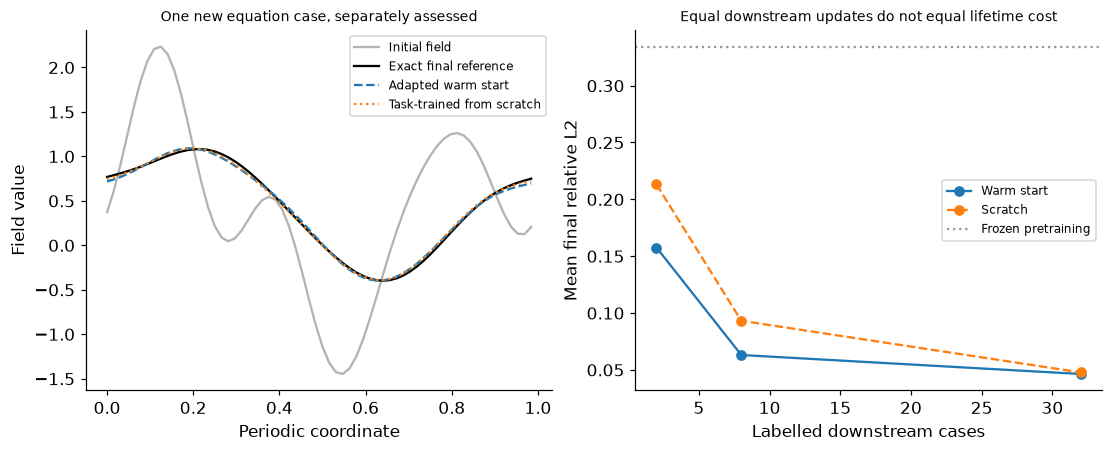

In [2]:
def cases(n,downstream=False):
    kappa=rng.uniform(.04,.06,n) if downstream else rng.uniform(.005,.025,n);velocity=rng.uniform(.6,.9,n) if downstream else rng.uniform(-.4,.4,n);reaction=np.full(n,.2) if downstream else rng.choice([0,.1],n);duration=rng.uniform(.05,.2,n);coeff=np.stack([kappa,velocity,reaction,duration],1).astype(np.float32);x=np.arange(64)/64;u=rng.normal(0,.5,(n,1))*np.ones((n,64))
    for mode in range(1,5):u+=rng.normal(0,1/mode,(n,1))*np.sin(2*np.pi*mode*x)+rng.normal(0,1/mode,(n,1))*np.cos(2*np.pi*mode*x)
    spectrum=np.fft.rfft(u);wave=2*np.pi*np.arange(spectrum.shape[1]);factor=np.exp((-kappa[:,None]*wave**2-reaction[:,None]-1j*velocity[:,None]*wave)*duration[:,None]);target=np.fft.irfft(spectrum*factor,n=64);return torch.tensor(u.astype(np.float32)),torch.tensor(coeff),torch.tensor(target.astype(np.float32))
SX,SC,SY=cases(512);DX,DC,DY=cases(128);TX,TC,TY=cases(32,True);VX,VC,VY=cases(16,True);FX,FC,FY=cases(64,True)
class SpectralTransfer(nn.Module):
    def __init__(self):super().__init__();self.factor=nn.Sequential(nn.Linear(4,48),nn.GELU(),nn.Linear(48,48),nn.GELU(),nn.Linear(48,18));self.register_buffer('scale',torch.tensor([.02,.4,.1,.1]))
    def forward(self,u,c):
        z=torch.fft.rfft(u);f=self.factor(c/self.scale).reshape(-1,9,2);complex_factor=torch.complex(f[:,:,0],f[:,:,1]);out=torch.cat([z[:,:9]*complex_factor,torch.zeros_like(z[:,9:])],dim=1);return torch.fft.irfft(out,n=u.shape[1])
base=SpectralTransfer();optimizer=torch.optim.Adam(base.parameters(),lr=.002);best=np.inf;trace=[]
for step in range(1500):
    ids=torch.tensor(rng.choice(512,32,replace=False));optimizer.zero_grad();loss=(base(SX[ids],SC[ids])-SY[ids]).square().mean();loss.backward();optimizer.step()
    if (step+1)%100==0:
        with torch.no_grad():score=float((base(DX,DC)-DY).square().mean())
        trace.append((step+1,score))
        if score<best:best=score;best_step=step+1;state=copy.deepcopy(base.state_dict())
base.load_state_dict(state);base.eval()
def relative_error(pred,truth):return float(torch.mean(torch.linalg.vector_norm(pred-truth,dim=1)/torch.linalg.vector_norm(truth,dim=1)))
with torch.no_grad():frozen_prediction=base(FX,FC);frozen_error=relative_error(frozen_prediction,FY)
rows=[];selected_states={};fit_records=[]
for budget in [2,8,32]:
    for route in ['Warm start','Scratch']:
        torch.manual_seed(SEED+budget);model=copy.deepcopy(base) if route=='Warm start' else SpectralTransfer();opt=torch.optim.Adam(model.parameters(),lr=.002);best_dev=np.inf
        for step in range(200):
            opt.zero_grad();loss=(model(TX[:budget],TC[:budget])-TY[:budget]).square().mean();loss.backward();opt.step()
            if (step+1)%50==0:
                with torch.no_grad():score=relative_error(model(VX,VC),VY)
                if score<best_dev:best_dev=score;selected=step+1;selected_state=copy.deepcopy(model.state_dict())
        model.load_state_dict(selected_state);model.eval()
        with torch.no_grad():prediction=model(FX,FC);final_error=relative_error(prediction,FY)
        rows.append({'route':route,'downstream_cases':budget,'development_cases':16,'selected_update':selected,'development_relative_L2':best_dev,'final_relative_L2':final_error});selected_states[(route,budget)]=model;fit_records.append({'route':route,'budget':budget,'optimizer_updates':200,'learning_rate':.002})
with torch.no_grad():
    selected=selected_states[('Warm start',32)];half=FC.clone();half[:,3]*=.5;one=selected(FX,FC);two=selected(selected(FX,half),half);semigroup=relative_error(two,one);mass_expected=FX.mean(1)*torch.exp(-FC[:,2]*FC[:,3]);mass_error=float(torch.mean(torch.abs(one.mean(1)-mass_expected)));scratch_prediction=selected_states[('Scratch',32)](FX,FC)
# Independent analytic semigroup and mean-law checks on a final case, in float64.
u=FX[0].numpy().astype(float);c=FC[0].numpy().astype(float);wave=2*np.pi*np.arange(33);factor=np.exp((-c[0]*wave**2-c[2]-1j*c[1]*wave)*c[3]);reference=np.fft.irfft(np.fft.rfft(u)*factor,n=64);reference_half=np.fft.irfft(np.fft.rfft(np.fft.irfft(np.fft.rfft(u)*np.exp((-c[0]*wave**2-c[2]-1j*c[1]*wave)*c[3]/2),n=64))*np.exp((-c[0]*wave**2-c[2]-1j*c[1]*wave)*c[3]/2),n=64);np.testing.assert_allclose(reference,reference_half,atol=1e-12,rtol=0);np.testing.assert_allclose(reference.mean(),u.mean()*np.exp(-c[2]*c[3]),atol=1e-12,rtol=0)
RESULTS.update(source_cases=512,source_development_cases=128,downstream_available_cases=32,downstream_development_cases=16,final_cases=64,grid_points=64,retained_modes=9,pretraining_updates=1500,selected_pretraining_update=best_step,source_development_MSE=best,parameters=sum(p.numel() for p in base.parameters()),frozen_final_relative_L2=frozen_error,adaptation=rows,fit_budgets=fit_records,adapted_semigroup_relative_defect=semigroup,adapted_mean_law_MAE=mass_error,named_scientific_checkpoint_executed=False);display(pd.DataFrame(rows));print('Frozen relative L2:',frozen_error,'Semigroup defect:',semigroup,'Mean-law error:',mass_error)
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(64)/64;axes[0].plot(xx,FX[0].numpy(),color='.7',label='Initial field');axes[0].plot(xx,FY[0].numpy(),color='black',label='Exact final reference');axes[0].plot(xx,one[0].numpy(),linestyle='--',label='Adapted warm start');axes[0].plot(xx,scratch_prediction[0].numpy(),linestyle=':',label='Task-trained from scratch');axes[0].set(xlabel='Periodic coordinate',ylabel='Field value',title='One new equation case, separately assessed');axes[0].legend(fontsize=8)
for route,style in [('Warm start','-'),('Scratch','--')]:axes[1].plot([2,8,32],[r['final_relative_L2'] for r in rows if r['route']==route],marker='o',linestyle=style,label=route)
axes[1].axhline(frozen_error,color='.6',linestyle=':',label='Frozen pretraining');axes[1].set(xlabel='Labelled downstream cases',ylabel='Mean final relative L2',title='Equal downstream updates do not equal lifetime cost');axes[1].legend(fontsize=8);plt.show()


<a id="scientific-support-map"></a>
 ## Keep the scientific family and units visible
 The source operator spans periodic, one-dimensional, linear advection–diffusion–reaction problems. It does not cover unknown geometries, nonlinear fluid turbulence or atmospheric variable conventions. Exact target fields are generated by the declared Fourier semigroup. The neural multiplier learns that mapping approximately, so reaction-adjusted mean evolution and two-half-step agreement remain independent checks. They are not automatically guaranteed by low field loss. Poseidon pretrains a different multiscale time-conditioned operator on fluid equations and uses downstream adaptation; Aurora operates on geophysical fields and task-specific fine-tuning. Their architecture, pretraining data and evidence belong to their primary reports, not this small original example. No published Poseidon/Aurora performance number is reproduced here.


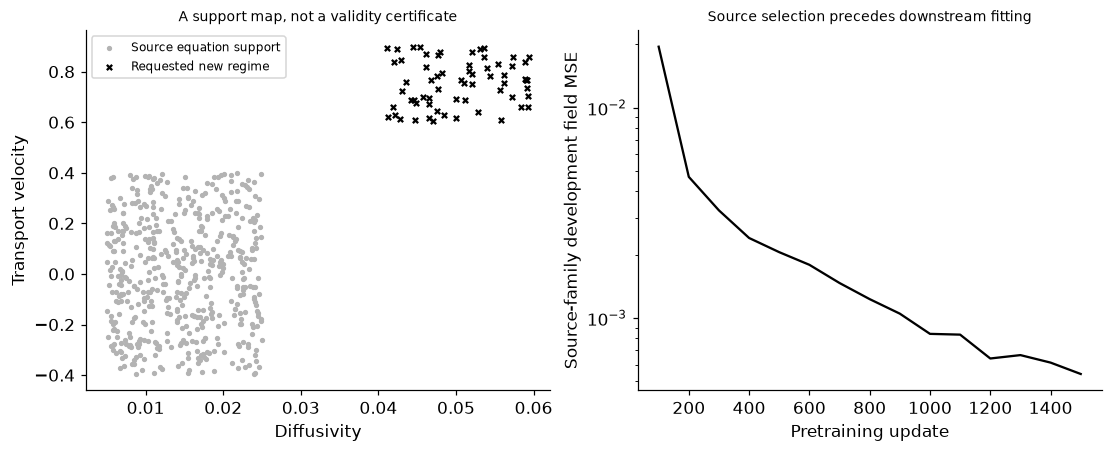

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(SC[:,0].numpy(),SC[:,1].numpy(),s=6,c='.7',label='Source equation support');axes[0].scatter(FC[:,0].numpy(),FC[:,1].numpy(),s=12,c='black',marker='x',label='Requested new regime');axes[0].set(xlabel='Diffusivity',ylabel='Transport velocity',title='A support map, not a validity certificate');axes[0].legend(fontsize=8)
h=np.array(trace);axes[1].semilogy(h[:,0],h[:,1],color='black');axes[1].set(xlabel='Pretraining update',ylabel='Source-family development field MSE',title='Source selection precedes downstream fitting');plt.show()
assert len(rows)==6 and len(fit_records)==6 and np.isfinite(semigroup) and mass_error>=0


In [4]:
summary={'example_id':'code_153','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual original spectral solution-operator pretraining across equation parameters', 'analytic periodic advection diffusion reaction references', 'whole-case development and downstream parameter updates', 'warm-start versus scratch operators with equal downstream budgets', 'physical support and semigroup consistency checks without named-model substitution'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual original spectral solution-operator pretraining across equation parameters", "analytic periodic advection diffusion reaction references", "whole-case development and downstream parameter updates", "warm-start versus scratch operators with equal downstream budgets", "physical support and semigroup consistency checks without named-model substitution"], "elapsed_seconds": 0.745, "example_id": "code_153", "hardware": "Darwin arm64 CPU", "results": {"adaptation": [{"development_cases": 16, "development_relative_L2": 0.18925276398658752, "downstream_cases": 2, "final_relative_L2": 0.1576175093650818, "route": "Warm start", "selected_update": 200}, {"development_cases": 16, "development_relative_L2": 0.2331567406654358, "downstream_cases": 2, "final_relative_L2": 0.2131032943725586, "route": "Scratch", "selected_update": 100}, {"development_cases": 16, "development_relative_L2": 0.06301914155483246, "downstream_cases": 8, "final_relati